# 1.0 Initial exploration

Goal: understand the sensor data before writing cleaning rules (stage 3, see docs/03-eda.md).

Data: data/interim/*.parquet, **2022-2023 only**. 2024 is the locked test year.


In [5]:
import calendar

import matplotlib.pyplot as plt
import polars as pl

from madrid_congestion.config import FIGURES_DIR, INTERIM_DATA_DIR

EDA_MONTHS = [f"{year}-{month:02d}" for year in (2022, 2023) for month in range(1, 13)]
SLOTS_PER_DAY = 96
print(len(EDA_MONTHS), EDA_MONTHS[0], EDA_MONTHS[-1], INTERIM_DATA_DIR)

24 2022-01 2023-12 E:\Madrid-traffic-ageing_Advanced project\madrid-congestion\data\interim


In [12]:
rows = []
for month in EDA_MONTHS:
    year, month_number = int(month[:4]), int(month[5:])
    slots_in_month = calendar.monthrange(year, month_number)[1] * SLOTS_PER_DAY
    df = pl.read_parquet(INTERIM_DATA_DIR / f"{month}.parquet", columns=["id", "ocupacion"])
    per_sensor = (
        df.group_by("id")
        .agg(valid=pl.col("ocupacion").count())
        .with_columns(
            month=pl.lit(month),
            share=pl.col("valid") / slots_in_month
        )
    )
    rows.append(per_sensor)

availability = pl.concat(rows)
availability.head()
availability.describe()

statistic,id,valid,month,share
str,f64,f64,str,f64
"""count""",106281.0,106281.0,"""106281""",106281.0
"""null_count""",0.0,0.0,"""0""",0.0
"""mean""",37816.183137,2761.643963,null,0.945698
"""std""",5.4585e6,462.875967,null,0.155864
"""min""",495.0,1.0,"""2022-01""",0.000336
"""25%""",4597.0,2792.0,null,0.96875
"""50%""",5787.0,2879.0,null,0.994097
"""75%""",7094.0,2964.0,null,0.998958
"""max""",1.1409e9,2976.0,"""2023-12""",1.0


In [13]:
print(availability.height)
availability["share"].describe()

106281


statistic,value
str,f64
"""count""",106281.0
"""null_count""",0.0
"""mean""",0.945698
"""std""",0.155864
"""min""",0.000336
"""25%""",0.96875
"""50%""",0.994097
"""75%""",0.998958
"""max""",1.0


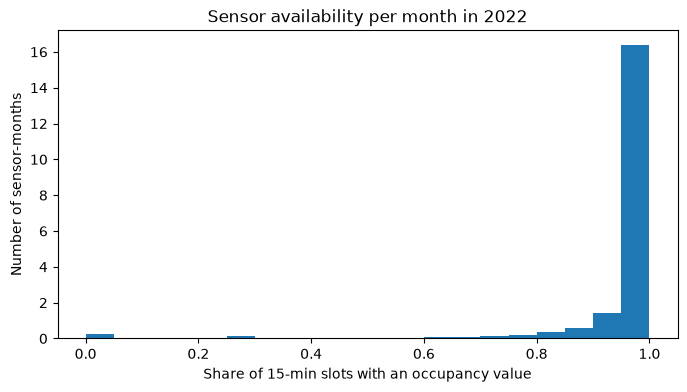

In [14]:
share_2022 = availability.filter(pl.col("month").str.starts_with("2022"))["share"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(share_2022, bins=20, density=True)
ax.set(
    title="Sensor availability per month in 2022",
    xlabel="Share of 15-min slots with an occupancy value",
    ylabel="Number of sensor-months",
)
plt.show()

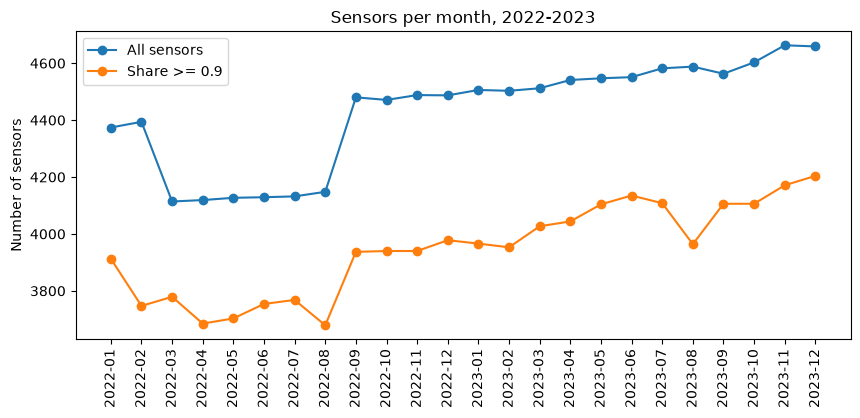

In [ ]:
per_month = (
    availability.group_by("month")
    .agg(
        n_sensors=pl.len(),
        n_reliable=(pl.col("share") >= 0.9).sum(),   # TODO later: try 0.8 and 0.95 too
    )
    .sort("month")
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(per_month["month"], per_month["n_sensors"], marker="o", label="All sensors")
ax.plot(per_month["month"], per_month["n_reliable"], marker="o", label="Share >= 0.9")
ax.set(title="Sensors per month, 2022-2023", ylabel="Number of sensors")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.show()